In [1]:
import subprocess
import sys

COLAB = "google.colab" in sys.modules


def _install(package):
    if COLAB:
        ans = input(f"Install { package }? [y/n]:")
        if ans.lower() in ["y", "yes"]:
            subprocess.check_call(
                [sys.executable, "-m", "pip", "install", "--quiet", package]
            )
            print(f"{ package } installed!")


def _colab_install_missing_deps(deps):
    import importlib

    for dep in deps:
        if importlib.util.find_spec(dep) is None:
            if dep == "iris":
                dep = "scitools-iris"
            _install(dep)


deps = ["ioos_qc"]
_colab_install_missing_deps(deps)

#   IOOS QARTOD on Glider Data
Created: 2026-10-02

Updated: 2026-10-22

During the 2026 Google Summer of Code, a project was [proposed to evaluate](https://github.com/ioos/gsoc/issues/102) the tests present in the [QARTOD glider manual](https://cdn.ioos.noaa.gov/media/2017/12/Manual-for-QC-of-Glider-Data_05_09_16.pdf), which had recently turned 10 years old. The final project was called ["Filling the gaps within the IOOS quality control schema for ocean glider data"](https://summerofcode.withgoogle.com/programs/2026/projects/bJGGUbsA) which led to a [series of investigative notebooks](https://github.com/Klankers/mau_gsoc_qartod) that did the following for tests listed within the manual:
1. Looked at the manual's description and assessed if it made sense.
2. Looked within the [IOOS QC codebase](https://github.com/ioos/ioos_qc/tree/main/ioos_qc) and assessed if it was authentic and genuine to the manual. If not, look at where the differences were and what they would do in practice.
3. Given the unknown recent activity of the manual's original authors, make additions or changes to the QARTOD toolbox to more comprehensively perform what is described in the manual.

This general procedure was done for the following tests:
1. Timing/Gap Test
2. Syntax Test
3. Location Test
4. Gross Range Test
5. Pressure Test
6. Climatology Test
14. (As ordered in the manual) Density Inversion Test

This notebook seeks to demonstrate how the tests can be used on ocean glider datasets. Unfortunately, the following tests were not assessed:

7. Spike Test
8. Rate of Change Test
9. Flat Line TEst
10. Multi-Variate Test
11. Attenuated Signal Test
12. Previous Profile Test
13. TS Curve/Space Test

As such, these tests will not be listed in this notebook unless updated at a later date.

Experimentation during the 2026 Google Summer of Code was commonly done on gliders using the [OG1 format](https://oceangliderscommunity.github.io/OG-format-user-manual/OG_Format.html). Plots, statistics, and any other outputs from this notebook are therefore entirely intended for educational purposes and are not intended to critically reflect on the dataset being used. Note that the results and settings present in this notebook may differ from those found at other institutions.

Data for this notebook is sourced from the Voice of the Ocean Foundation's ALSEAMAR *SeaExplorer* fleet, operating in the [Skagerrak](https://en.wikipedia.org/wiki/Skagerrak) between 2021 and 2026. This region is characterized by the interaction between deep, salty water from the [North Sea](https://en.wikipedia.org/wiki/North_Sea) interacting with fresh, relatively warm outflow from the [Baltic Sea](https://en.wikipedia.org/wiki/Baltic_Sea), passing through the [Danish Straits](https://en.wikipedia.org/wiki/Danish_Straits) and [Kattegat](https://en.wikipedia.org/wiki/Kattegat). This gives a temperature profile that is normally expected (warmest water at the surface), though the salinity profile is opposite of that typical in ocean gyres or open ocean (here, fresh water is on top).

The dataset to be used is [mission #109 of SeaExplorer number 044](https://erddap.observations.voiceoftheocean.org/erddap/files/OG_complete_SEA044_M109/), operating for 20 days in September 2025.

## Load the data
Starting with imports and loading the dataset.

In [2]:
from ioos_qc import qartod
import pooch
import xarray as xr

url = "https://erddap.observations.voiceoftheocean.org/erddap/files/OG_complete_SEA044_M109/"
fname = "sea044_20250905T0639_delayed.nc"
filehash = "0bce25b78fc40bd7888a76909faa60b4f6490afd44b68a7f1f56c9d7611020ab"
#   VOTO's file hashes are not public as of September 2026. I've computed it using Python's 'hashlib'

download = pooch.retrieve(
    url=f"{url}{fname}",
    known_hash=f"sha256:{filehash}"
)
ds = xr.open_dataset(download)
ds

<xarray.Dataset> Size: 245MB
Dimensions:                             (N_MEASUREMENTS: 1699082)
Coordinates:
  * N_MEASUREMENTS                      (N_MEASUREMENTS) int64 14MB 0 ... 169...
    LATITUDE                            (N_MEASUREMENTS) float64 14MB ...
    LONGITUDE                           (N_MEASUREMENTS) float64 14MB ...
    TIME                                (N_MEASUREMENTS) datetime64[ns] 14MB ...
    DEPTH                               (N_MEASUREMENTS) float64 14MB ...
Data variables: (12/31)
    AD2CP_HEADING                       (N_MEASUREMENTS) float32 7MB ...
    AD2CP_PITCH                         (N_MEASUREMENTS) float32 7MB ...
    AD2CP_ROLL                          (N_MEASUREMENTS) float32 7MB ...
    BBP700                              (N_MEASUREMENTS) float32 7MB ...
    CHLA                                (N_MEASUREMENTS) float32 7MB ...
    DIVE_NUMBER                         (N_MEASUREMENTS) int64 14MB ...
    ...                                  ...
    SENSOR_CURRENT_PROFILERS_105527     float64 8B ...
    SENSOR_DISSOLVED_GAS_SENSORS_0095   float64 8B ...
    SENSOR_FLUOROMETERS_235280          float64 8B ...
    SENSOR_MICROSTRUCTURE_SENSORS_0496  float64 8B ...
    PROFILE_NUMBER                      (N_MEASUREMENTS) int64 14MB ...
    PROFILE_DIRECTION                   (N_MEASUREMENTS) int64 14MB ...
Attributes: (12/67)
    Conventions:                                CF-1.10, OG-1.0, Unidata Data...
    acknowledgement:                            This study used data collecte...
    agency:                                     Voice of the Ocean
    agency_role:                                contact point
    agency_role_vocabulary:                     http://vocab.nerc.ac.uk/colle...
    cdm_data_type:                              Trajectory
    ...                                         ...
    start_date:                                 20250905T0639
    basin:                                      Skagerrak
    total_dives:                                616
    dataset_id:                                 delayed_SEA044_M109
    data_url:                                   https://erddap.observations.v...
    variables:                                  ['AD2CP_HEADING', 'AD2CP_PITC...

## A note on flags
A quick disclaimer that all flags in this notebook adhere to a set defined in the QARTOD data flags manual (not just the glider manual) and [UNESCO 2013](https://www.ioccp.org/images/D4standards/IOC-OceanDataStandards54-3-2013.pdf). There are 5 flags described:

| Flag | Meaning | Definition |
|------|---------|------------|
| 1 | GOOD | Passed documented required QC tests |
| 2 | UNKNOWN (not evaluated) | Used for data when no QC test performed or the information on quality is not available |
| 3 | SUSPECT | Failed non‐critical documented metric or subjective test(s) |
| 4 | FAIL | Failed critical documented QC test(s) or as assigned by the data provider |
| 9 | MISSING | Used as place holder when data are missing |

Note that these flags differ from those used at other institutions (Argo, for example, has flag=0 for UNKNOWN).

In [3]:
from ioos_qc.qartod import QartodFlags

#   Importing the flags, but also tying them to a color for some plotting later.
flag_style = {
    QartodFlags.GOOD:    ("GOOD", "#77AC30"),
    QartodFlags.UNKNOWN: ("UNKNOWN", "#4DBEEE"),
    QartodFlags.SUSPECT: ("SUSPECT", "#EDB120"),
    QartodFlags.FAIL:    ("FAIL", "#A2142F"),
    QartodFlags.MISSING: ("MISSING", "#7F7F7F"),
}

## Helper functions
Below are a handful of helper functions, just for formatting some common outputs and reformatting plots.

QARTOD commonly flags by cascading flags onto one another by severity. I.e., everything is untested (2) until it is passed into a test, where it is considered good. If *anything* goes wrong, this good flag is overwritten by a missing flag (9, typically handled with a numpy mask), a suspect flag (3), or straight up failing (4).

In [4]:
order = [QartodFlags.UNKNOWN, QartodFlags.GOOD, QartodFlags.MISSING, QartodFlags.SUSPECT, QartodFlags.FAIL]

* First helper - quickly prints how many points receive each of the potential flags in a numpy masked array
* Second helper - a scatter for ordering each of the flags. This should make it easier to see certain flags over each other.
* Third helper - for formatting dates on an axis
* Fourth helper - geographic plotting with `roaring_landmask`

In [5]:
def flag_counts(flags, name=""):
    flags = np.ma.getdata(flags)
    parts = [
        f"{flag_style[f][0]}={np.count_nonzero(flags == f):,}" for f in order if np.any(flags == f)
    ]
    print(f"{name:<28s}" + ", ".join(parts))

In [6]:
def plot_flags(ax, x, y, flags, s=4, thin=1, legend=True, **kwargs):
    x, y, flags = np.asarray(x), np.asarray(y), np.ma.getdata(flags)
    for zorder, f in enumerate(order):
        idx = np.flatnonzero(flags == f)
        if idx.size == 0:   #   No flags of this type, skip rather than break
            continue
        label, color = flag_style[f]
        size = s
        if f == QartodFlags.GOOD:
            idx = idx[::thin]
        else:
            size = 4 * s
        ax.scatter(
            x[idx],
            y[idx],
            s=size,
            color=color,
            linewidths=0,
            label=f"{label} ({np.count_nonzero(flags == f):,})",
            zorder=2 + zorder,
            rasterized=True,
            **kwargs,
        )
    if legend:
        ax.legend(loc="best", markerscale=2, fontsize=8)

In [7]:
#   A way to quickly format date axes
import matplotlib.dates as mdates
def date_axis(ax, fmt="%d %b"):
    ax.xaxis.set_major_formatter(mdates.DateFormatter(fmt)) #   Pull this out

We'll use the routine below for visualizing geospatial extent for the range of the dataset (which ranges from about lat (57, 59) deg N, lon (8, 11) deg E).

In [8]:
def land_background(ax, extent, res=0.01):
    lon_g = np.arange(extent[0], extent[1] + res, res)
    lat_g = np.arange(extent[2], extent[3] + res, res)
    lon_m, lat_m = np.meshgrid(lon_g, lat_g)
    land = landmask.contains_many(lon_m.ravel(), lat_m.ravel()).reshape(lon_m.shape)
    ax.contourf(lon_m, lat_m, land, levels=[0.5, 1.5], zorder=0)
    ax.contour(lon_m, lat_m, land, levels=[0.5], linewidths=0.5, zorder=1)
    ax.set_xlim(extent[:2])
    ax.set_ylim(extent[2:])
    #   Keep distances roughly true by correcting for the convergence of meridians
    ax.set_aspect(1 / np.cos(np.deg2rad(np.mean(extent[2:]))))
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")

## Preliminary data check
Let's take a quick look at the data now that we've got it loaded and some helpers up and running, while also deriving some parameters we'll use later.
* PSAL - practical salinity from conductivity.
* SA - absolute salinity from practical salinity.
* CT - conservative temperature, coming from absolute salinity and the original temperature
* SIGMA0 - or $\sigma_\theta$, typically described as the potential density referenced to the surface.

We can get these with `gsw`, which uses the TEOS-10 algorithms.

In [9]:
import gsw
import numpy as np
ds["PSAL"] = gsw.SP_from_C(ds.CNDC, ds.TEMP, ds.PRES)
ds["SA"] = gsw.SA_from_SP(ds.PSAL, ds.PRES, ds.LONGITUDE, ds.LATITUDE)
ds["CT"] = gsw.CT_from_t(ds.SA, ds.TEMP, ds.PRES)
ds["SIGMA0"] = gsw.sigma0(ds.SA, ds.CT)

time = ds.TIME.values
pres = ds.PRES.values
temp = ds.TEMP.values
psal = ds.PSAL.values
sigma0 = ds.SIGMA0.values
profile = ds.PROFILE_NUMBER.values
direction = ds.PROFILE_DIRECTION.values  # 1 = descending, -1 = ascending

print(f"{time.size} measurements in {np.unique(profile).size} profiles")
print(f"{np.datetime_as_string(time[0], unit='m')} to {np.datetime_as_string(time[-1], unit='m')}")

1699082 measurements in 1232 profiles
2025-09-05T06:39 to 2025-09-25T09:24


And of course, we should look at the data from a geospatial perspective. In the `location_on_land` test, this is done using the package `roaring_landmask` for high-resolution coastlines.

In [10]:
from roaring_landmask import RoaringLandmask
landmask = RoaringLandmask.new()

In [11]:
extent = (8.8, 11.6, 57.4, 59.2)  # lon_min, lon_max, lat_min, lat_max

[None, None, None, None, None, None]

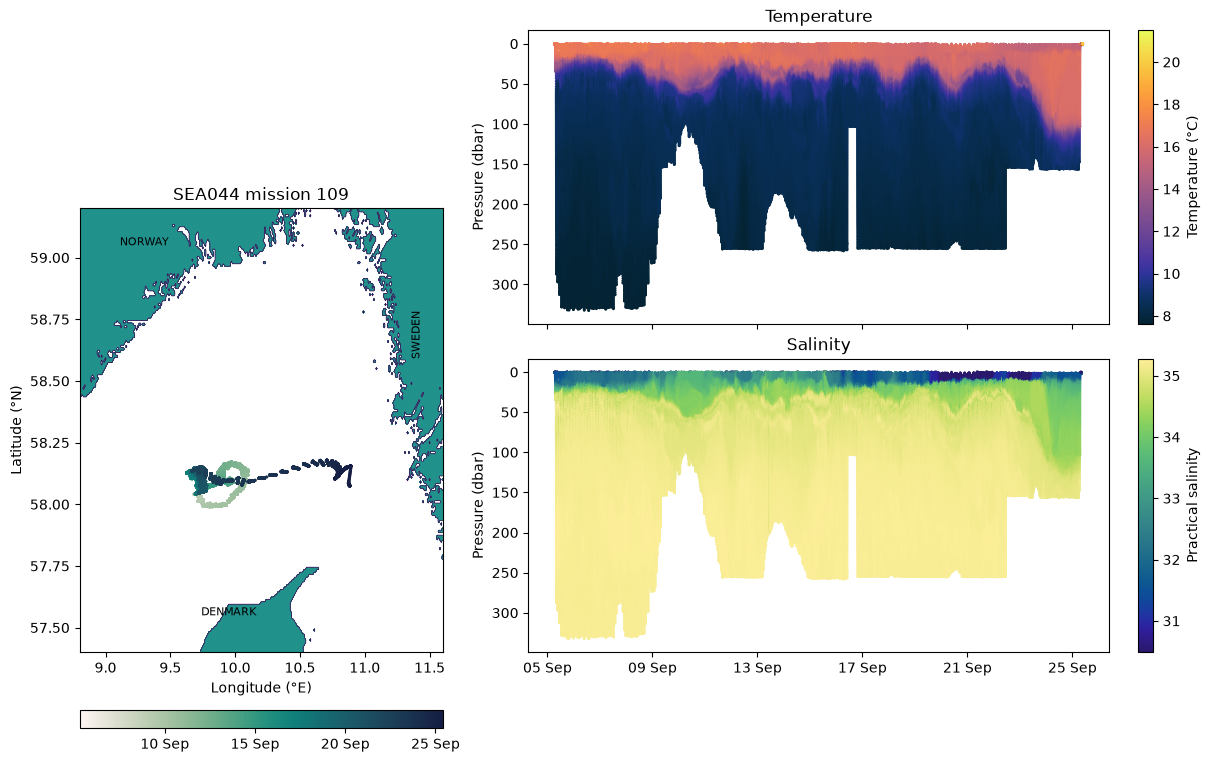

In [12]:
import matplotlib.pyplot as plt
import cmocean
fig = plt.figure(figsize=(12, 7.5), layout="constrained")
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.6])
ax_map = fig.add_subplot(gs[:, 0])
ax_t = fig.add_subplot(gs[0, 1])
ax_s = fig.add_subplot(gs[1, 1], sharex=ax_t, sharey=ax_t)

land_background(ax_map, extent=extent)
step = 50
sc = ax_map.scatter(
    ds.LONGITUDE.values[::step], ds.LATITUDE.values[::step], c=mdates.date2num(time[::step]),
    s=2, cmap=cmocean.cm.tempo, rasterized=True,
)
cb = fig.colorbar(sc, ax=ax_map, orientation="horizontal", pad=0.02)
cb.ax.xaxis.set_major_locator(mdates.DayLocator(interval=5))
cb.ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax_map.text(9.95, 57.55, "DENMARK", ha="center", fontsize=8)
ax_map.text(9.3, 59.05, "NORWAY", ha="center", fontsize=8)
ax_map.text(11.4, 58.6, "SWEDEN", ha="center", fontsize=8, rotation=90)
ax_map.set_title("SEA044 mission 109")

step = 10
for ax, var, cmap, label in [
    (ax_t, temp, cmocean.cm.thermal, "Temperature (°C)"),
    (ax_s, psal, cmocean.cm.haline, "Practical salinity"),
]:
    sc = ax.scatter(time[::step], pres[::step], c=var[::step], s=1, cmap=cmap, rasterized=True)
    if var is psal:
        sc.set_clim(np.nanpercentile(psal, [1, 99.9]))
    fig.colorbar(sc, ax=ax, label=label)
    ax.set_ylabel("Pressure (dbar)")
ax_t.invert_yaxis()
ax_t.set_title("Temperature")
ax_s.set_title("Salinity")
date_axis(ax_s)
plt.setp(ax_t.get_xticklabels(), visible=False)

This shows that the glider started up and did a loop, before transitioning closer to Sweden (most likely for recovery).

## Timing/Gap Test
This test was not present in the toolbox prior to GSoC, mostly because there was not a clear consensus in the community of exactly what it should look like or do. Gliders do not provide a data stream as they cannot communicate while underwater. Instead, they bundle the most recent data and communicate that over satellite.

With this context in mind, it made sense to break this test up into 3 use cases:
1. Impossible dates. I.e., something that will check the `TIME` coordinate or variable and ensure that it adheres to a "reasonable" round, like how the manual describes it.
  * Data is either present or in the past.
  * Month, day, hour, minute are all possible (Numpy datetime64 does not tolerate impossible values)
  * Include user-specified tolerances. If the glider was deployed last week, you wouldn't expect a datetime from 4 years ago.
2. Data reception. The manual describes a `TIM_INC` increment to flag data by if they're older than that. This is potentially more handy for data centers, as they'll be *expecting* data at certain intervals. For example, you could have a glider that is returning totally reasonable datetimes, they're just not coming in as recent as you've specified.
3. Time gaps. This is perhaps the most obvious one that can't really be assessed in real-time, but if the glider doesn't record a data point within an expected period, that gap should be flagged. This is a helpful test for finding inconsistencies in glider reporting - helpful for engineering troubleshooting or when working with time-series analyses that are sensitive to uneven sampling rates.

### Impossible Dates
This test runs with an optional argument with a `fail_span`, used to designate a user-defined window of times where data can be potentially bad.

To demonstrate this, let's inject some fake data and show the `fail_span` in action.

In [13]:
time_bad = time.copy()
injected = {
    200000: np.datetime64("2031-02-14T12:00:00"),  #    in the future
    600000: np.datetime64("1970-01-01T00:00:00"),  #    Unix epoch
    900000: np.datetime64("2025-08-15T00:00:00"),  #    before the deployment
    1200000: np.datetime64("NaT", "ns"),  # missing
}
for i, t in injected.items():
    time_bad[i] = t

deployed = ds.DEPLOYMENT_TIME.values
window = (deployed, deployed + np.timedelta64(30, "D")) #   Let's say we add 30 days or so from the beginning of the deployment.

flags_date = qartod.impossible_date_test(time_bad)
flags_date_window = qartod.impossible_date_test(time_bad, fail_span=window)

flag_counts(flags_date, "No window:")
flag_counts(flags_date_window, "Deployment window:")

No window:                  GOOD=1,699,080, MISSING=1, FAIL=1
Deployment window:          GOOD=1,699,078, MISSING=1, FAIL=3


As you can see above, only one data point fails without using the `fail_span`, since the default `impossible_date_test` is just looking for values that can't logically happen (accounting for time travelers). The only point that fails is the value from 2031, whereas adding the window further constrains what is acceptable.

Text(50000.0, 2025-10-05T06:39:47.000000000, 'deployment window')

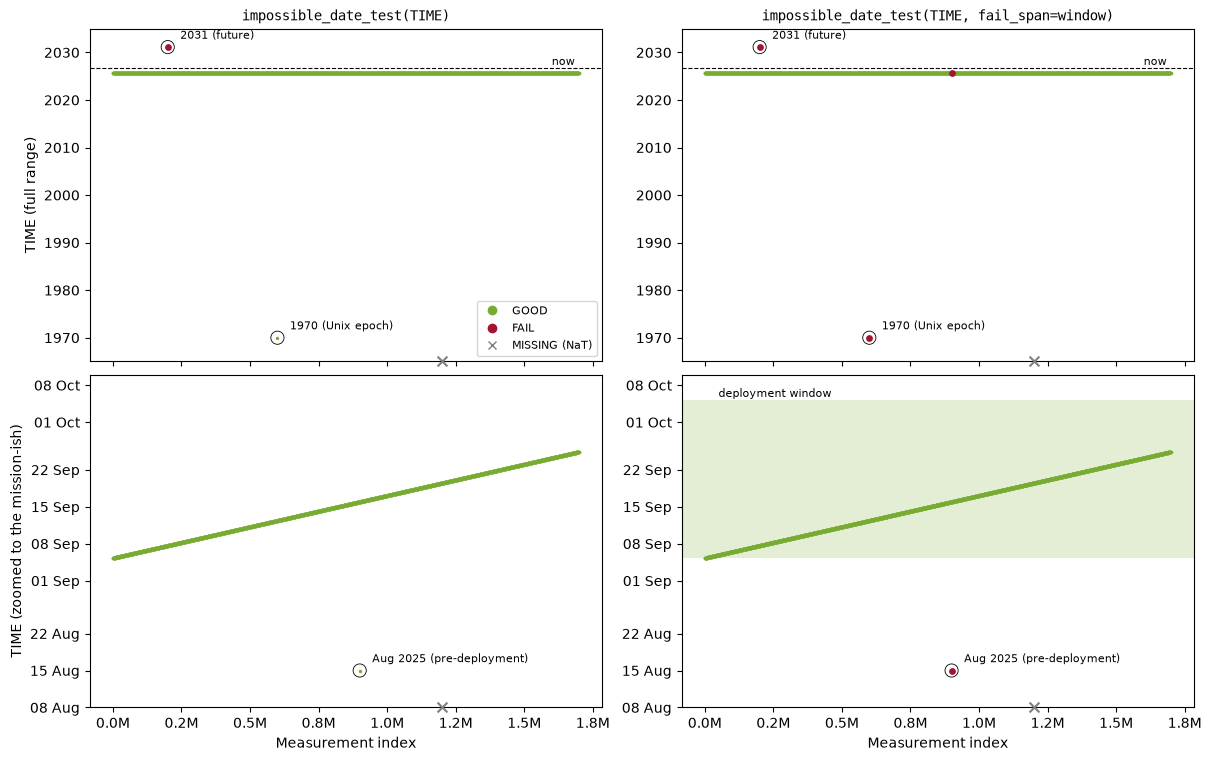

In [14]:
idx = np.unique(np.r_[np.arange(0, time_bad.size, 500), list(injected)])
nat = np.isnat(time_bad[idx])
labels = {200000: "2031 (future)", 600000: "1970 (Unix epoch)", 900000: "Aug 2025 (pre-deployment)"}
ylims = [
    (np.datetime64("1965-01-01"), np.datetime64("2035-01-01")),
    (np.datetime64("2025-08-08"), np.datetime64("2025-10-10")),
]

fig, axs = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True, layout="constrained")
for col, (flags, title) in enumerate([
    (flags_date, "impossible_date_test(TIME)"),
    (flags_date_window, "impossible_date_test(TIME, fail_span=window)"),
]):
    for row, ylim in enumerate(ylims):
        ax = axs[row, col]
        plot_flags(ax, idx[~nat], time_bad[idx][~nat], np.ma.getdata(flags)[idx][~nat], s=6, legend=False)
        ax.scatter(idx[nat], np.full(nat.sum(), ylim[0]), marker="x", color=flag_style[9][1], s=50, clip_on=False, zorder=10)
        ax.set_ylim(ylim)
        if col == 1:
            ax.axhspan(*window, color=flag_style[1][1], alpha=0.2, lw=0)
        for i, text in labels.items():
            #   Ring each injected timestamp, and label it where it stands apart from the mission
            off_mission = row == 1 or not (window[0] - np.timedelta64(60, "D") < time_bad[i] < window[1])
            if ylim[0] < time_bad[i] < ylim[1] and off_mission:
                ax.scatter(i, time_bad[i], s=90, facecolors="none", edgecolors="k", linewidths=0.6, zorder=10)
                ax.annotate(text, xy=(i, time_bad[i]), xytext=(9, 6), textcoords="offset points", fontsize=8)
    axs[0, col].set_title(title, fontfamily="monospace", fontsize=10)
    axs[0, col].axhline(np.datetime64("now"), color="k", ls="--", lw=0.8)
    axs[0, col].text(time_bad.size, np.datetime64("now"), "now ", ha="right", va="bottom", fontsize=8)
    axs[1, col].set_xlabel("Measurement index")
    axs[1, col].yaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    axs[1, col].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e6:.1f}M"))
axs[0, 0].set_ylabel("TIME (full range)")
axs[1, 0].set_ylabel("TIME (zoomed to the mission-ish)")
axs[0, 0].legend(handles=[
    plt.Line2D([], [], marker="o", ls="", color=flag_style[f][1], label=flag_style[f][0]) for f in (1, 4)
] + [plt.Line2D([], [], marker="x", ls="", color=flag_style[9][1], label="MISSING (NaT)")], loc="lower right", fontsize=8)
axs[1, 1].text(5e4, window[1], "deployment window", va="bottom", fontsize=8)

### Data Reception
The data reception test originated from a potential use for data centers. Let's pretend the check happens 10 days into the mission (`from_time`):
* data more than 48 h older than `from_time` is stale, so **FAIL**,
* data within 48 h of `from_time` is **GOOD**,
* data *newer* than `from_time` is not judged by this test and passes through as **GOOD**.

With the default `from_time` (now), every point in a 2025 dataset is stale. If you're reading this and running this notebook, your data will all be stale on the original dataset as well.

The test is not meant for archived data like this! It's a kind of a gap test intended for use by a listener and pairs best with NRT data.

In [15]:
check_time = time[0] + np.timedelta64(10, "D")  #   Need to assign based on time[0] plus some offset
max_age_hours = 48

flags_rx = qartod.data_reception_test(time, fail_span=max_age_hours, from_time=check_time)
flag_counts(flags_rx, f"from_time = {np.datetime_as_string(check_time, unit='h')}:")
flag_counts(qartod.data_reception_test(time, fail_span=max_age_hours), "from_time = now:")

from_time = 2025-09-15T06:  GOOD=1,023,164, FAIL=675,918
from_time = now:            FAIL=1,699,082


So with the span defined, we can see that the data is more or less split, which we're expecting given the mission is longer than what we speicified at 10 days duration.

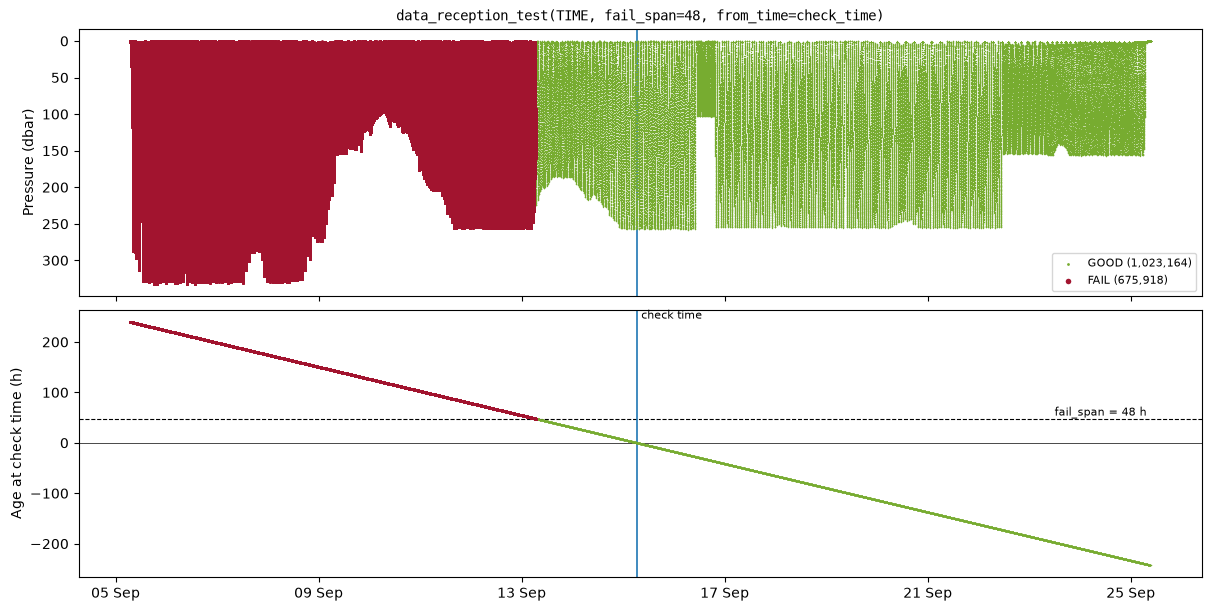

In [16]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True, layout="constrained")
#   Data considered "stale"
plot_flags(axs[0], time, pres, flags_rx, s=1, thin=10)
axs[0].invert_yaxis()
axs[0].set_ylabel("Pressure (dbar)")
axs[0].set_title(f"data_reception_test(TIME, fail_span={max_age_hours}, from_time=check_time)", fontfamily="monospace", fontsize=10)

#   Age of the data in hours - relative to our check time
age_hours = (check_time - time) / np.timedelta64(1, "h")
plot_flags(axs[1], time, age_hours, flags_rx, s=1, thin=100, legend=False)
axs[1].axhline(max_age_hours, color="k", ls="--", lw=0.8)
axs[1].text(time[-1], max_age_hours, f"fail_span = {max_age_hours} h ", ha="right", va="bottom", fontsize=8)
axs[1].axhline(0, color="k", lw=0.5)
axs[1].set_ylabel("Age at check time (h)")
for ax in axs:
    ax.axvline(check_time, lw=1.2)
axs[1].text(check_time, axs[1].get_ylim()[1], " check time", va="top", fontsize=8)
date_axis(axs[1])
plt.show()

### Time Gaps
Next comes the first thing that a user is probably thinking of when it comes to a time/gap test - where is my data not spaced appropriately? Where are the holes in my data?

This is also where the duplicate timestamps noticed during GSoC'26 show up: thousands of steps are exactly zero. They are not gaps, so `time_gap_test` doesn't flag them, but they are worth knowing about and might warrant further exploration.

In [17]:
dt_seconds = np.diff(time) / np.timedelta64(1, "s")
print(f"Median step: {np.median(dt_seconds)} s, longest: {dt_seconds.max()} s, zero-length (duplicates): {np.count_nonzero(dt_seconds == 0)}")

Median step: 1.0 s, longest: 125.0 s, zero-length (duplicates): 4500


In the data loaded here, most data points are spaced at about a second apart. However, there are some real gaps that can arise.

In [18]:
flag_counts(qartod.time_gap_test(time), "fail_span = 2 h:")
flag_counts(qartod.time_gap_test(time, fail_span=1 / 60), "fail_span = 1 min:")

fail_span = 2 h:            GOOD=1,699,082
fail_span = 1 min:          GOOD=1,699,072, FAIL=10


As you can see above, the default limit of two hours doesn't find anything - which says more about our data than the test! There are only a few points that are a minute or longer. The point that *follwos* the gap is what is flagged.

To see a real gap we can simulate a data dropout by deleting six hours of measurements from the middle of the mission, as might happen if a data file was lost. Then we run the test with its default 2 h `fail_span`.

In [19]:
gap_start = np.datetime64("2025-09-15T06:00")
gap_end = gap_start + np.timedelta64(6, "h")
keep = (time < gap_start) | (time >= gap_end)

time_gappy = time[keep]
pres_gappy = pres[keep]
flags_gap = qartod.time_gap_test(time_gappy, fail_span=2)
flag_counts(flags_gap, "Simulated dropout:")
print("Flagged point:", np.datetime_as_string(time_gappy[np.ma.getdata(flags_gap) == QartodFlags.FAIL][0], unit="s"))

Simulated dropout:          GOOD=1,677,961, FAIL=1
Flagged point: 2025-09-15T12:00:00


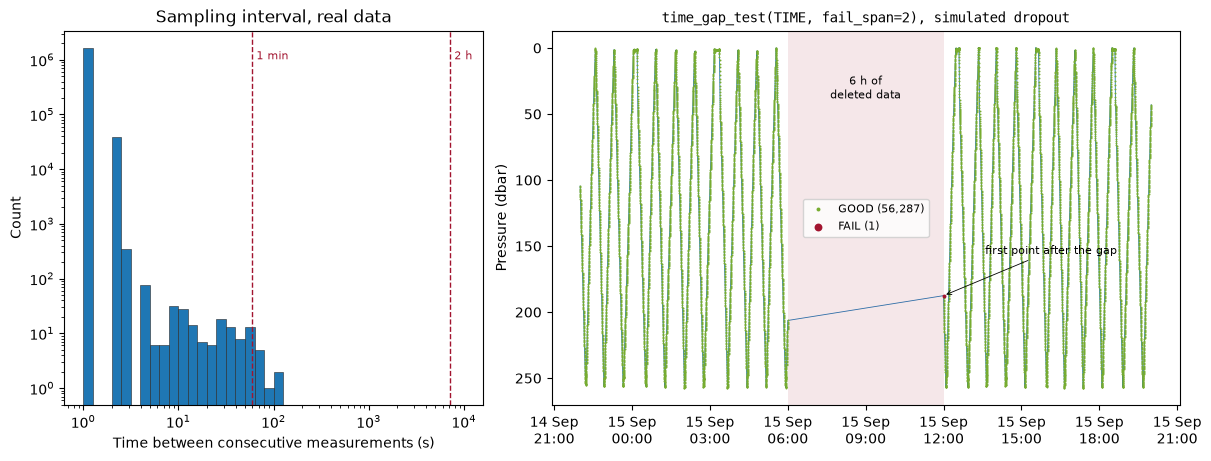

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained", width_ratios=[1, 1.5])   #   A binned hist, with a vis of the timeseries with a hole in it
bins = np.logspace(0, 4, 41)
axs[0].hist(np.clip(dt_seconds, 1, None), bins=bins, edgecolor="#262626", linewidth=0.4)
axs[0].set_xscale("log")
axs[0].set_yscale("log")
for span, label in [(60, "1 min"), (7200, "2 h")]:
    axs[0].axvline(span, color=flag_style[4][1], ls="--", lw=1)
    axs[0].text(span, axs[0].get_ylim()[1] * 0.3, f" {label}", color=flag_style[4][1], fontsize=8)
axs[0].set_xlabel("Time between consecutive measurements (s)")
axs[0].set_ylabel("Count")
axs[0].set_title("Sampling interval, real data")

near = (time_gappy > gap_start - np.timedelta64(8, "h")) & (time_gappy < gap_end + np.timedelta64(8, "h"))
axs[1].plot(time_gappy[near], pres_gappy[near],lw=0.6,zorder=1)
plot_flags(axs[1], time_gappy[near], pres_gappy[near], np.ma.getdata(flags_gap)[near], s=2, thin=5, legend=False)
axs[1].legend(loc="center", markerscale=2, fontsize=8)
axs[1].axvspan(gap_start, gap_end, color=flag_style[4][1], alpha=0.1, lw=0)
axs[1].text(gap_start + (gap_end - gap_start) / 2, 20, "6 h of\ndeleted data", ha="center", va="top", fontsize=8)
axs[1].annotate("first point after the gap", xy=(gap_end, pres_gappy[np.ma.getdata(flags_gap) == QartodFlags.FAIL][0]),
                xytext=(30, 30), textcoords="offset points", fontsize=8, arrowprops={"arrowstyle": "->", "lw": 0.6})
axs[1].invert_yaxis()
axs[1].set_ylabel("Pressure (dbar)")
axs[1].set_title("time_gap_test(TIME, fail_span=2), simulated dropout", fontfamily="monospace", fontsize=10)
date_axis(axs[1], "%d %b\n%H:%M")
plt.show()

## Syntax Test
This is a test that is described in the manual to a certain extent, but was also very polarizing when discussing with indiviual glider groups. How do you test something that differs wildly from glider model to glider model, with some manufacturers not having "raw" data available at all? Possibly a relic of the zeitgeist prior to the major glider manufacturers of the 2020s, the syntax test has been implemented here to be more generic for some of the raw messages that a glider can transmit. These messages are hard to get a hand of, but the basic function can still be applied to real-world data even though our data is in OG1 format.

The syntax test works on the **raw messages** a glider sends, before they are parsed into numbers. Common among these is HEX or hexadecimal format, which can then be parsed into bytes.
> CF010502AF02470085010101169217199E9401AD85091F48979B004662240E - an example HEX string from Argo.

So there are multiple ways that the data could be parsed - it could be a HEX-encoded string like above, or a more conventional list of characters, perhaps with a delimiter (like glider NMEA strings).

Each message is checked for having the expected length, measured in one of three ways:
* `lentype="char"`: number of characters,
* `lentype="byte"`: number of bytes in a HEX-encoded string (two characters per byte),
* `delimiter=";"`: number of fields once the message is split on a delimiter.

Putting this into practice, let's rebuild some semicolon-delimited records with time, state, pressure, T, and C to test the `char` argument. Kinda like a fake NMEA. Then we can "damage" it, something that a cycle redundancy check would look for.
* Truncation - when data gets cut off
* Dropping a field - like if for whatever reason a sensor goes offline
* Stray char - when something isn't collapsed correctly in the raw data or some static noise is introduced through a bad config
* Records merged - very common on CTDs when writing to a physical disk too slowly, missing the newline

In [29]:
ix = 500000
n_meas = 40
sub = slice(ix, ix+n_meas)
records = []
for t, nav, p, tc, c in zip(
    time[sub],
    ds.NAV_RESOURCE.values[sub],
    pres[sub],
    temp[sub],
    ds.CNDC.values[sub],
    strict=True,
):
    records.append(
        f"{np.datetime_as_string(t, unit='ms')};"
        f"{nav:03.0f};{p:08.3f};{tc:07.4f};{c:07.4f}"
    )
good_len = len(records[0])
good_field = len(records[0].split(";"))
print(f"{len(records)} items: {records}")
print(f"Good length = {good_len} characters. Good field length = {good_field}")

40 items: ['2025-09-11T04:41:49.000;118;0200.145;08.0313;36.5509', '2025-09-11T04:41:50.000;118;0200.207;08.0303;36.5479', '2025-09-11T04:41:51.000;118;0200.258;08.0287;36.5464', '2025-09-11T04:41:52.000;118;0200.299;08.0273;36.5465', '2025-09-11T04:41:53.000;118;0200.321;08.0273;36.5486', '2025-09-11T04:41:54.000;118;0200.331;08.0254;36.5453', '2025-09-11T04:41:55.000;118;0200.331;08.0254;36.5457', '2025-09-11T04:41:56.000;118;0200.312;08.0239;36.5448', '2025-09-11T04:41:57.000;118;0200.274;08.0239;36.5457', '2025-09-11T04:41:58.000;118;0200.230;08.0233;36.5467', '2025-09-11T04:41:59.000;118;0200.176;08.0233;36.5461', '2025-09-11T04:42:00.000;118;0200.105;08.0240;36.5458', '2025-09-11T04:42:01.000;118;0200.024;08.0241;36.5453', '2025-09-11T04:42:02.000;118;0199.927;08.0235;36.5458', '2025-09-11T04:42:03.000;118;0199.826;08.0236;36.5459', '2025-09-11T04:42:04.000;118;0199.706;08.0238;36.5459', '2025-09-11T04:42:05.000;118;0199.579;08.0237;36.5461', '2025-09-11T04:42:06.000;118;0199.438

A good record is 52 characters long, with 5 fields.

In [30]:
print("And these are the damaged guys:")
print(f"Nothing wrong:      {records[0]}")
#   By index to transform the line
damage = {
    6: ("truncated", lambda r: r[:-3]),  # transmission cut off
    15: ("field dropped", lambda r: ";".join(r.split(";")[:3] + r.split(";")[4:])),
    24: ("stray character", lambda r: r[:30] + "#" + r[30:]),
    33: ("records merged", lambda r: r + records[34]),
}
for i, (what, fn) in damage.items():
    records[i] = fn(records[i])
    print(f"{i:>2d} {what:<16s} {records[i]}")
records = np.array(records)

And these are the damaged guys:
Nothing wrong:      2025-09-11T04:41:49.000;118;0200.145;08.0313;36.5509
 6 truncated        2025-09-11T04:41:55.000;118;0200.331;08.0254;36.5
15 field dropped    2025-09-11T04:42:04.000;118;0199.706;36.5459
24 stray character  2025-09-11T04:42:13.000;118;01#98.307;08.0246;36.5467
33 records merged   2025-09-11T04:42:22.000;118;0196.500;08.0314;36.55432025-09-11T04:42:23.000;118;0196.299;08.0352;36.5582


We can run this two ways: By **counting characters** or delimited **fields**.

In [31]:
flags_char = qartod.syntax_test(records, nchar=good_len, lentype="char")
flags_field = qartod.syntax_test(records, nchar=good_field, delimiter=";")
flag_counts(flags_char, "By characters:")
flag_counts(flags_field, "By fields:")

By characters:              GOOD=36, FAIL=4
By fields:                  GOOD=38, FAIL=2


The two methods catch different problems:
* **Counting characters** catches all four, but only because we used a fixed-width format. If the numbers were written with variable width (e.g. `9.87` vs `10.12`), healthy records would differ in length and fail too.
* **Counting fields** is robust to variable-width numbers, but it misses the truncated record (the cut-off is inside the last field, so there are still 5 fields) and the stray character (no extra `;`).

So each has limitations.

When it comes to `lentype="byte"`, each HEX byte itself is two characters. So strings of odd lengths will fail right away.

In [32]:
hex_records = np.array([
    "0AEE61154B95811CEF0B8FB3140016FE8107A45F44FFFB6DFF595A386319612EE2C05B7371",  # 37 bytes
    "0AEE61154B95811CEF0B8FB3140016FE8107A45F44FFFB6DFF595A386319612EE2C05B737",   # odd length
    "0AEE61154B95811CEF0B8FB3140016FE8107A45F44FFFB6DFF595A386319612EE2C05B",      # 36 bytes
])
print(qartod.syntax_test(hex_records, nchar=37, lentype="byte"))

[1 4 4]


So the first line was successful because it satisftied the `nchar` "byte-type" `lentype`, the second line failed because it is an odd length, an the third line was too short.

Visualizing the results is probably easiest with a bar of different lengths. The number of characters, and the number of fields, can change the length overall expected length.

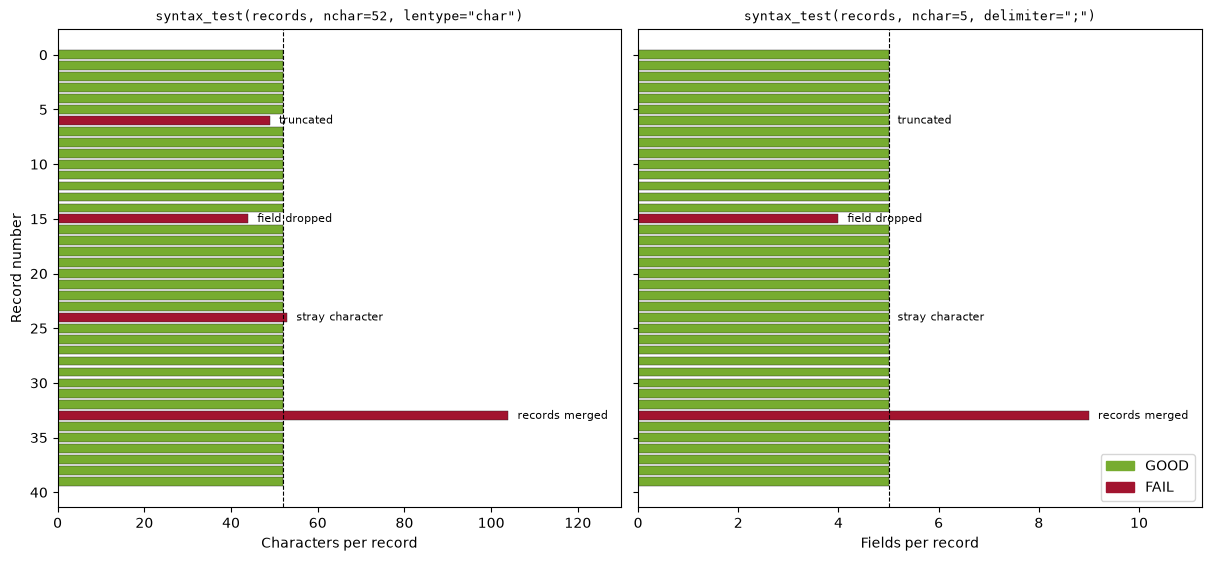

In [33]:
n_chars = np.char.str_len(records)
n_fields = np.array([len(r.split(";")) for r in records])
rec = np.arange(records.size)

fig, axs = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True, layout="constrained")
for ax, values, expected, flags, title in [
    (axs[0], n_chars, good_len, flags_char, f'syntax_test(records, nchar={good_len}, lentype="char")'),
    (axs[1], n_fields, good_field, flags_field, 'syntax_test(records, nchar=5, delimiter=";")'),
]:
    colors = [flag_style[f][1] for f in np.ma.getdata(flags)]
    ax.barh(rec, values, color=colors, edgecolor="#262626", linewidth=0.3, height=0.8)
    ax.axvline(expected, color="k", ls="--", lw=0.8)
    ax.set_title(title, fontfamily="monospace", fontsize=9)
    ax.set_xlim(0, values.max() * 1.25)
    for i, (what, _) in damage.items():
        ax.text(values[i] + values.max() * 0.02, i, what, va="center", fontsize=8)
axs[0].set_xlabel("Characters per record")
axs[1].set_xlabel("Fields per record")
axs[0].set_ylabel("Record number")
axs[0].invert_yaxis()
axs[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=flag_style[f][1], label=flag_style[f][0]) for f in (1, 4)], loc="lower right")
plt.show()

## Location Test
The location test, following the 2026 GSoC, has been expanded into additional tests based on the description of intended functionalities described in the manual.
* Location test - reworked to handle basic lat/lon bounds and (optionally) defined distances between points.
* Location *on land* test - flagging points that are detected to be on land, using the GSHHG coastline database for quick, high-resolution results.
* Location *bounds* test - expanding on the original `location` test by taking a user-defined coordinate shape (not just a rectangle) and then flagging either inside or outside of a range. Handy when chaining areas together, such as MPAs inside of a survey area.



### New Location Test

### Location on Land Test

### Location Bounds

## Gross Range Test

## Percentile Range Test
Grew from Gross Range, as suggested by my mentor, Callum.

## Pressure Test

## Climatology Test

## Density Inversion Test